In [1]:
from lab3 import *

### Функция f1(x) = sin(x)

Функция f1 представляет собой синусоидальную зависимость y = sin(x). Она является нелинейной и периодической, поэтому позволяет оценить способность моделей аппроксимировать плавные изменения целевой функции.

### Сравнение моделей

| Модель      | MSE | RMSE | MAE | R² | MAPE, % | Качество, % |
|-------------|---:|---:|---:|---:|---:|---:|
| sklearn MLP | 0.000435 | 0.020856 | 0.010395 | 0.998948 | 4.0318 | 99.50 |
| PyTorch MLP | 0.000034 | 0.005796 | 0.003631 | 0.999920 | 1.7217 | 100.00 |
| RBF         | 0.000006 | 0.002434 | 0.001282 | 0.999986 | 0.3880 | 100.00 |
| RBF (Adam)  | 0.000312 | 0.017676 | 0.005988 | 0.999244 | 1.6274 | 99.75 |
| ANFIS       | 0.000017 | 0.004109 | 0.003115 | 0.999959 | 2.1074 | 100.00 |

### Вывод

Все рассмотренные модели показали высокое качество аппроксимации функции f1. Наилучший результат продемонстрировала модель RBF в первом эксперименте: она имеет минимальные значения MSE (0.000006), RMSE (0.002434), MAE (0.001282) и MAPE (0.3880%), а также максимальный коэффициент детерминации R² = 0.999986.

Модель ANFIS и нейросеть PyTorch также показали высокую точность, однако несколько уступили первой модели RBF. Наименее точный результат получен у sklearn MLP, хотя его качество аппроксимации также составило 99.50%.

Таким образом, для аппроксимации функции f1 наилучшей оказалась модель RBF из первого эксперимента.

In [7]:
X_f1 = np.random.normal(loc=0.0, scale=1.0, size=(1000, 1))
y_f1 = np.sin(X_f1).ravel()

X_train_f1, X_test_f1, y_train_f1, y_test_f1 = train_test_split(
    X_f1, y_f1, test_size=0.4, random_state=123
)

model_path = "best_net_f1.pkl"

if os.path.exists(model_path):
    best_net_f1 = joblib.load(model_path)
    print("Загружена сохранённая модель.")

else:
    net_f1 = MLPRegressor(random_state=0)

    params_f1 = {
        "hidden_layer_sizes": [(5,), (10,), (10, 10), (20, 10)],
        "activation": ["tanh", "relu"],
        "solver": ["adam"],
        "learning_rate_init": [0.001, 0.005, 0.01],
        "alpha": [0.0001, 0.001, 0.01],
        "max_iter": [1000]
    }

    random_search = RandomizedSearchCV(
        estimator=net_f1,
        param_distributions=params_f1,
        n_iter=20,
        scoring="r2",
        cv=5,
        random_state=42,
        n_jobs=-1
    )

    random_search.fit(X_train_f1, y_train_f1)

    best_net_f1 = random_search.best_estimator_

    joblib.dump(best_net_f1, model_path)

    print("Модель обучена и сохранена.")
    print("Лучшие параметры:", random_search.best_params_)
    print("Лучший R2 на кросс-валидации:", random_search.best_score_)

pred_f1 = best_net_f1.predict(X_test_f1)

print("R2 на тесте:", r2_score(y_test_f1, pred_f1))
m = MetricsCalculator()

metrics_f1 = m.calculate_comprehensive_metrics(
    y_true=y_test_f1,
    y_pred=pred_f1,
    model_name="sklearn: f1(x) = sin(x)"
)

quality_f1 = m.approximation_quality(
    deviation=0.1,
    y_pred=pred_f1,
    y_true=y_test_f1
)

print(f"Качество аппроксимации: {quality_f1:.2f}%")
visualize_and_evaluate_2d_model(X_test_f1, y_test_f1, pred_f1, "Аппроксимация f1(x) = sin(x)")


Загружена сохранённая модель.
R2 на тесте: 0.9983285526884627

sklearn: f1(x) = sin(x) - МЕТРИКИ КАЧЕСТВА:
----------------------------------------
MSE:  0.000686
RMSE: 0.026186
MAE:  0.012142
R²:   0.998329
MAPE: 4.5899%
Качество аппроксимации: 99.25%


In [8]:
inputs = torch.tensor(X_train_f1, dtype=torch.float32)
targets = torch.tensor(
    np.asarray(y_train_f1).reshape(-1, 1),
    dtype=torch.float32
)

model_path = "best_MLPnet_f1.pth"


class MLP(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, 10)
        self.fc3 = nn.Linear(10, output_size)

    def forward(self, x):
        out = F.relu(self.fc1(x))
        out = F.relu(self.fc2(out))
        out = self.fc3(out)
        return out


input_size = inputs.size(1)
hidden_size = 20
output_size = 1

model = MLP(input_size, hidden_size, output_size)

if os.path.exists(model_path):
    model.load_state_dict(
        torch.load(model_path, weights_only=True)
    )
    print("Загружена сохранённая модель.")

else:
    num_epoch = 1000
    learning_rate = 0.01

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
        weight_decay=1e-4
    )

    loss_fct = nn.MSELoss()

    training_samples = utils_data.TensorDataset(inputs, targets)
    data_loader_trn = utils_data.DataLoader(
        training_samples,
        batch_size=200,
        drop_last=False,
        shuffle=True
    )

    for epoch in range(num_epoch):
        c_loss = 0

        for data, target in data_loader_trn:
            pred = model(data.float())
            loss = loss_fct(pred, target.float())

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            c_loss += loss.item()

        if epoch % 10 == 0:
            print(
                f"Epoch [{epoch + 1}/{num_epoch}], "
                f"Loss: {c_loss:.4f}"
            )

    torch.save(model.state_dict(), model_path)
    print("Модель обучена и сохранена.")
model.eval()

with torch.no_grad():
    final_prediction = model(inputs)

final_pred_np = final_prediction.cpu().numpy().ravel()
targets_np = targets.cpu().numpy().ravel()

print("Корреляция:",
      np.corrcoef(final_pred_np, targets_np)[0, 1])

metrics_f1 = m.calculate_comprehensive_metrics(
    y_true=targets_np,
    y_pred=final_pred_np,
    model_name="PyTorch: f1(x) = sin(x)"
)

quality_f1 = m.approximation_quality(
    deviation=0.1,
    y_pred=final_pred_np,
    y_true=targets_np
)

print(f"Качество аппроксимации: {quality_f1:.2f}%")
visualize_and_evaluate_2d_model(inputs, targets, final_pred_np, "Аппроксимация f1(x) = sin(x)")

Загружена сохранённая модель.
Корреляция: 0.9999835460176448

PyTorch: f1(x) = sin(x) - МЕТРИКИ КАЧЕСТВА:
----------------------------------------
MSE:  0.000020
RMSE: 0.004421
MAE:  0.003336
R²:   0.999955
MAPE: 1.3392%
Качество аппроксимации: 100.00%


Загружена сохранённая модель RBF.
Нейрон 1: центр = [1.574179], sigma = 0.6916, beta = 1.0453
Нейрон 2: центр = [-0.20277211], sigma = 0.3501, beta = 4.0796
Нейрон 3: центр = [-2.08127127], sigma = 0.7535, beta = 0.8807
Нейрон 4: центр = [0.33992025], sigma = 0.3862, beta = 3.3519
Нейрон 5: центр = [-0.75061622], sigma = 0.3804, beta = 3.4553
Нейрон 6: центр = [0.65170421], sigma = 0.4413, beta = 2.5675
Нейрон 7: центр = [2.20022466], sigma = 1.0075, beta = 0.4926
Нейрон 8: центр = [-1.49107835], sigma = 0.5855, beta = 1.4585
Нейрон 9: центр = [1.04782652], sigma = 0.5435, beta = 1.6929
Нейрон 10: центр = [-2.735427], sigma = 1.1896, beta = 0.3533
Нейрон 11: центр = [-0.47184385], sigma = 0.3518, beta = 4.0399
Нейрон 12: центр = [0.03572083], sigma = 0.3501, beta = 4.0796
Нейрон 13: центр = [3.44433603], sigma = 1.8369, beta = 0.1482
Нейрон 14: центр = [-1.06520153], sigma = 0.4446, beta = 2.5294


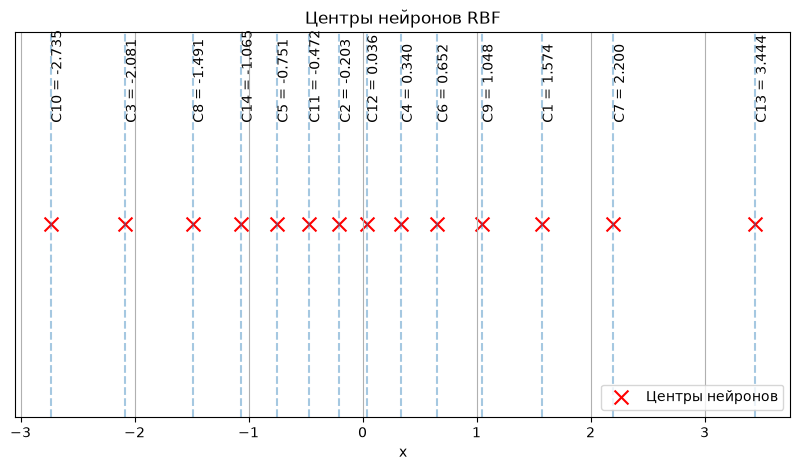

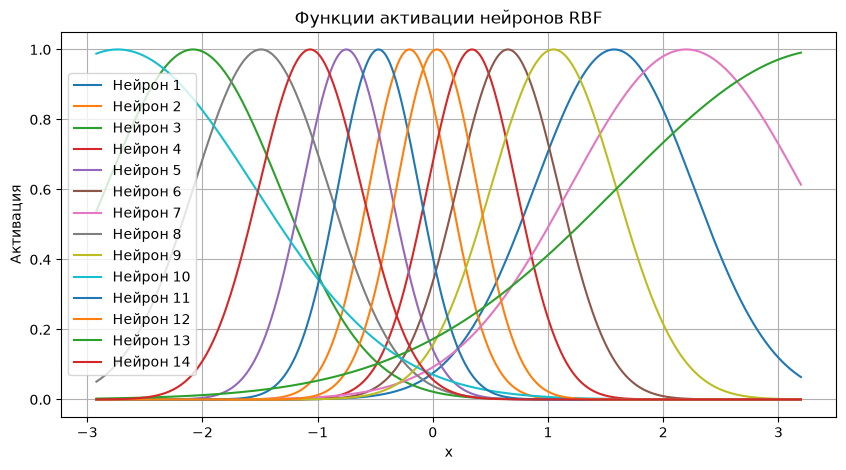

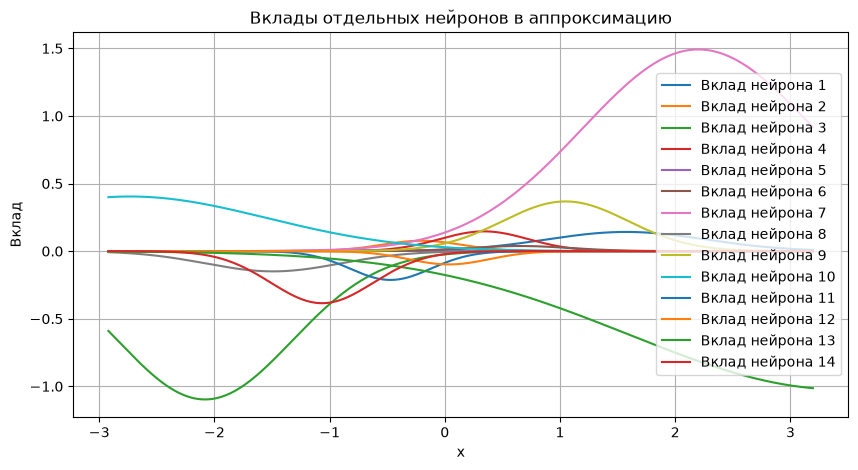

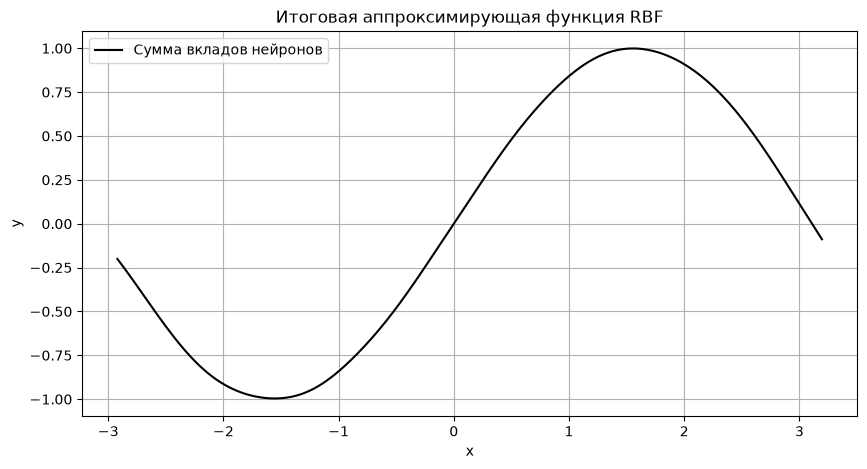

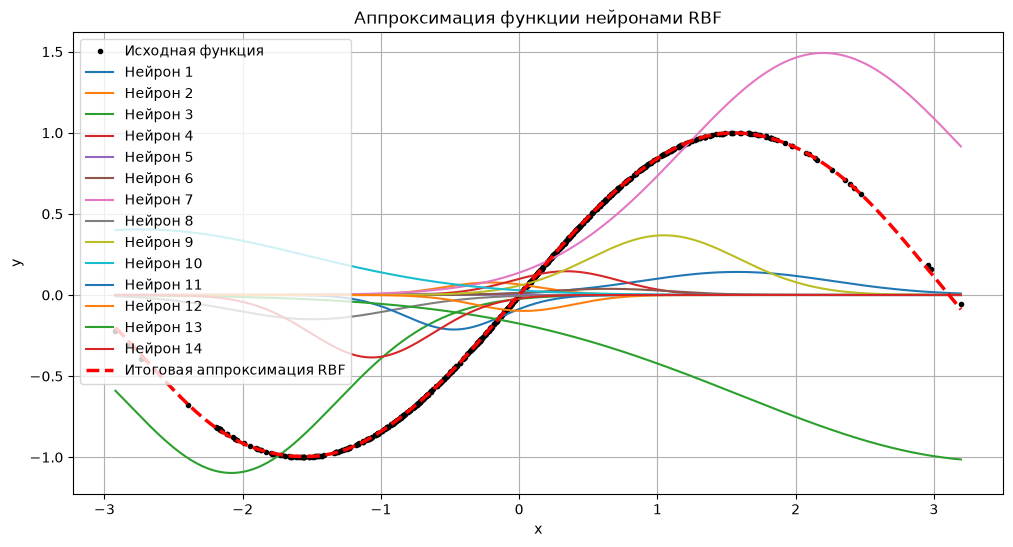


RBF: f1(x) = sin(x) - МЕТРИКИ КАЧЕСТВА:
----------------------------------------
MSE:  0.000006
RMSE: 0.002463
MAE:  0.001327
R²:   0.999985
MAPE: 0.4288%
Качество аппроксимации RBF: 100.00%


In [9]:
model_path = "best_RBF_f1.pkl"

if os.path.exists(model_path):
    rbf = joblib.load(model_path)
    print("Загружена сохранённая модель RBF.")

else:
    rbf = RBF(
        indim=1,
        numCenters=14,
        outdim=1
    )

    rbf.train(
        X_train_f1,
        y_train_f1.reshape(-1, 1)
    )

    joblib.dump(rbf, model_path)
    print("Модель RBF обучена и сохранена.")

for i in range(rbf.numCenters):
    print(
        f"Нейрон {i + 1}: "
        f"центр = {rbf.centers[i]}, "
        f"sigma = {rbf.sigmas[i]:.4f}, "
        f"beta = {1 / (2 * rbf.sigmas[i] ** 2):.4f}"
    )

rbf.plot_gaussians(
    X_train_f1,
    y_train_f1.reshape(-1, 1)
)

pred_test_rbf = rbf.test(X_test_f1).ravel()

m = MetricsCalculator()

metrics_rbf = m.calculate_comprehensive_metrics(
    y_true=y_test_f1,
    y_pred=pred_test_rbf,
    model_name="RBF: f1(x) = sin(x)"
)

quality_rbf = m.approximation_quality(
    deviation=0.1,
    y_pred=pred_test_rbf,
    y_true=y_test_f1
)

print(f"Качество аппроксимации RBF: {quality_rbf:.2f}%")
visualize_and_evaluate_2d_model(X_test_f1, y_test_f1, pred_test_rbf, "Аппроксимация f1(x) = sin(x)")

In [10]:
model_path = "best_RBFAdam_f1.pkl"

if os.path.exists(model_path):
    rbf = joblib.load(model_path)
    print("Загружена сохранённая модель RBF.")

else:
    rbf = RBF(
        indim=1,
        numCenters=14,
        outdim=1
    )

    rbf.train(
        X_train_f1,
        y_train_f1.reshape(-1, 1),
        adam=True
    )

    joblib.dump(rbf, model_path)
    print("Модель RBF обучена и сохранена.")

pred_test_rbf = rbf.test(X_test_f1).ravel()

for i in range(rbf.numCenters):
    print(
        f"Нейрон {i + 1}: "
        f"центр = {rbf.centers[i]}, "
        f"sigma = {rbf.sigmas[i]:.4f}, "
        f"beta = {1 / (2 * rbf.sigmas[i] ** 2):.4f}"
    )

m = MetricsCalculator()

metrics_rbf = m.calculate_comprehensive_metrics(
    y_true=y_test_f1,
    y_pred=pred_test_rbf,
    model_name="RBF: f1(x) = sin(x)"
)

quality_rbf = m.approximation_quality(
    deviation=0.1,
    y_pred=pred_test_rbf,
    y_true=y_test_f1
)

print(f"Качество аппроксимации RBF: {quality_rbf:.2f}%")
visualize_and_evaluate_2d_model(X_test_f1, y_test_f1, pred_test_rbf, "Аппроксимация f1(x) = sin(x)")

Загружена сохранённая модель RBF.
Нейрон 1: центр = [1.574179], sigma = 0.6916, beta = 1.0453
Нейрон 2: центр = [-0.20277211], sigma = 0.3501, beta = 4.0796
Нейрон 3: центр = [-2.08127127], sigma = 0.7535, beta = 0.8807
Нейрон 4: центр = [0.33992025], sigma = 0.3862, beta = 3.3519
Нейрон 5: центр = [-0.75061622], sigma = 0.3804, beta = 3.4553
Нейрон 6: центр = [0.65170421], sigma = 0.4413, beta = 2.5675
Нейрон 7: центр = [2.20022466], sigma = 1.0075, beta = 0.4926
Нейрон 8: центр = [-1.49107835], sigma = 0.5855, beta = 1.4585
Нейрон 9: центр = [1.04782652], sigma = 0.5435, beta = 1.6929
Нейрон 10: центр = [-2.735427], sigma = 1.1896, beta = 0.3533
Нейрон 11: центр = [-0.47184385], sigma = 0.3518, beta = 4.0399
Нейрон 12: центр = [0.03572083], sigma = 0.3501, beta = 4.0796
Нейрон 13: центр = [3.44433603], sigma = 1.8369, beta = 0.1482
Нейрон 14: центр = [-1.06520153], sigma = 0.4446, beta = 2.5294

RBF: f1(x) = sin(x) - МЕТРИКИ КАЧЕСТВА:
----------------------------------------
MSE:  0.

In [11]:
X_anfis_train, X_anfis_valid, y_anfis_train, y_anfis_valid = train_test_split(
    X_train_f1,
    y_train_f1,
    test_size=0.15,
    random_state=123
)

y_anfis_train = np.asarray(y_anfis_train).reshape(-1, 1)
y_anfis_valid = np.asarray(y_anfis_valid).reshape(-1, 1)

X_anfis_train = torch.as_tensor(
    X_anfis_train, dtype=torch.float32
)
y_anfis_train = torch.as_tensor(
    np.asarray(y_anfis_train).reshape(-1, 1),
    dtype=torch.float32
)

X_anfis_valid = torch.as_tensor(
    X_anfis_valid, dtype=torch.float32
)
y_anfis_valid = torch.as_tensor(
    np.asarray(y_anfis_valid).reshape(-1, 1),
    dtype=torch.float32
)


model_path = "best_ANFIS_f1.pth"

membfuncs = [
    {
        'function': 'gaussian',
        'n_memb': 3,
        'params': {
            'mu': {
                'value': [-1.0, 0.0, 1.0],
                'trainable': True
            },
            'sigma': {
                'value': [1.0, 1.0, 1.0],
                'trainable': True
            }
        }
    }
]

fis = SANFIS(
    membfuncs=membfuncs,
    n_input=1,
    scale='Std'
)

print_rules(fis, 'Правила до обучения')

if os.path.exists(model_path):
    checkpoint = torch.load(
        model_path,
        map_location='cpu',
        weights_only=False
    )

    fis.load_state_dict(checkpoint['model_state_dict'])

    fis.scaler = checkpoint['scaler']

else:

    loss_function = torch.nn.MSELoss(reduction='mean')

    optimizer = torch.optim.Adam(
        fis.parameters(),
        lr=0.005
    )

    history = fis.fit(
        train_data=[X_anfis_train, y_anfis_train],
        valid_data=[X_anfis_valid, y_anfis_valid],
        optimizer=optimizer,
        loss_function=loss_function,
        epochs=1000
    )

    torch.save({
        'model_state_dict': fis.state_dict(),
        'scaler': fis.scaler,
        'scaling_params': fis.scaling_params
    }, model_path)

    print("Загружена сохранённая модель ANFIS.")



print_rules(fis, 'Правила обученной ANFIS')

X_test_tensor = torch.as_tensor(
    X_test_f1, dtype=torch.float32
)

y_pred = fis.predict(X_test_tensor)
y_pred_anfis = np.asarray(y_pred).reshape(-1)

m = MetricsCalculator()

metrics_anfis = m.calculate_comprehensive_metrics(
    y_true=y_test_f1,
    y_pred=y_pred_anfis,
    model_name="ANFIS: f1(x) = sin(x)"
)

quality_anfis = m.approximation_quality(
    deviation=0.1,
    y_true=y_test_f1,
    y_pred=y_pred_anfis
)

print(f"Качество аппроксимации: {quality_anfis:.2f}%")

visualize_and_evaluate_2d_model(
    X_test_f1,
    y_test_f1,
    y_pred_anfis,
    "ANFIS: аппроксимация sin(x)"
)


Правила до обучения
Правило 1: ЕСЛИ x принадлежит A1 (mu=-1.0000, sigma=1.0000), ТО y = 0.0160x + 0.2031
Правило 2: ЕСЛИ x принадлежит A2 (mu=0.0000, sigma=1.0000), ТО y = -0.0495x + 0.3830
Правило 3: ЕСЛИ x принадлежит A3 (mu=1.0000, sigma=1.0000), ТО y = 0.1137x + 0.1298

Правила обученной ANFIS
Правило 1: ЕСЛИ x принадлежит A1 (mu=-2.4235, sigma=1.5501), ТО y = -1.0912x - 3.3010
Правило 2: ЕСЛИ x принадлежит A2 (mu=0.0783, sigma=1.3394), ТО y = 1.3916x - 0.0839
Правило 3: ЕСЛИ x принадлежит A3 (mu=2.2889, sigma=1.4994), ТО y = -1.3228x + 3.6873

ANFIS: f1(x) = sin(x) - МЕТРИКИ КАЧЕСТВА:
----------------------------------------
MSE:  0.000019
RMSE: 0.004398
MAE:  0.003260
R²:   0.999953
MAPE: 2.7137%
Качество аппроксимации: 100.00%
